Original Dataset:
   Practice_Tests_Completed  Placement_Eligible
0                         0                   0
1                         1                   0
2                         2                   0
3                         3                   1
4                         4                   1
5                         5                   1
6                         1                   0
7                         2                   0
8                         3                   1
9                         4                   1

Actual Values:
[0 0 1]

Predicted Values:
[0 0 1]

Model Accuracy: 1.0

Confusion Matrix:
[[2 0]
 [0 1]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         2
           1       1.00      1.00      1.00         1

    accuracy                           1.00         3
   macro avg       1.00      1.00      1.00         3
weighted avg       1.00      1.00      1.00         

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


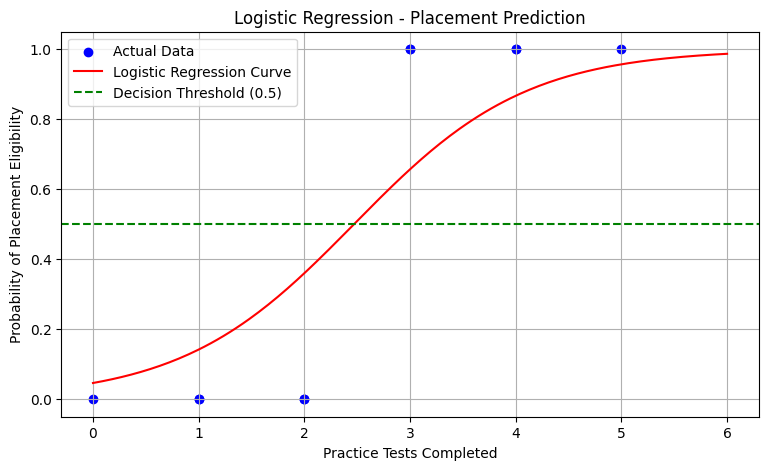

In [1]:

# Logistic Regression - Placement Eligibility Prediction

# 1. Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# 2. Create dataset
data = {
    'Practice_Tests_Completed': [0, 1, 2, 3, 4, 5, 1, 2, 3, 4],
    'Placement_Eligible': [0, 0, 0, 1, 1, 1, 0, 0, 1, 1]
}

df = pd.DataFrame(data)

print("Original Dataset:")
print(df)

# 3. Separate input and output
X = df[['Practice_Tests_Completed']]
y = df['Placement_Eligible']

# 4. Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

# 5. Create Logistic Regression model
model = LogisticRegression()

# 6. Train the model
model.fit(X_train, y_train)

# 7. Predict test data
y_pred = model.predict(X_test)

print("\nActual Values:")
print(y_test.values)

print("\nPredicted Values:")
print(y_pred)

# 8. Evaluate the model
accuracy = accuracy_score(y_test, y_pred)

print("\nModel Accuracy:", accuracy)
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

# 9. Predict placement eligibility for new students
new_students = pd.DataFrame({
    'Practice_Tests_Completed': [1, 2, 3, 4, 5, 6]
})

predictions = model.predict(new_students)
probabilities = model.predict_proba(new_students)[:, 1]

prediction_results = pd.DataFrame({
    'Practice_Tests_Completed': new_students[
        'Practice_Tests_Completed'
    ],
    'Predicted_Eligibility': predictions,
    'Eligibility_Probability': probabilities.round(3)
})

print("\nNew Student Predictions:")
print(prediction_results.to_string(index=False))

# 10. Visualize Logistic Regression
x_values = np.linspace(0, 6, 200).reshape(-1, 1)

prob = model.predict_proba(x_values)[:, 1]

plt.figure(figsize=(9, 5))

plt.scatter(
    X, y,
    color='blue',
    label='Actual Data'
)

plt.plot(
    x_values,
    prob,
    color='red',
    label='Logistic Regression Curve'
)

plt.axhline(
    y=0.5,
    color='green',
    linestyle='--',
    label='Decision Threshold (0.5)'
)

plt.xlabel('Practice Tests Completed')
plt.ylabel('Probability of Placement Eligibility')
plt.title('Logistic Regression - Placement Prediction')
plt.legend()
plt.grid(True)
plt.show()
